# Transformers and LLMs for Text Classification — AG News

Same two approaches as `imdb_transformer_llm.ipynb`, now on a **4-class** problem.

- **Part 1** — Build and train a Transformer classifier on the **AG News** topic dataset
- **Part 2** — Use a large language model (LLaMA via Groq) for zero-shot and few-shot classification

**Dataset (Part 1):** AG News — ~120 000 train / 7 600 test, 4 topic classes:

| Label | Topic |
|---|---|
| 0 | World |
| 1 | Sports |
| 2 | Business |
| 3 | Sci/Tech |

**Dataset (Part 2):** same AG News, but we only send a handful of examples to the LLM API

The structural changes from binary (IMDb) to 4 classes are exactly the ones seen in the previous session:
the output layer has **K units instead of 1**, the loss becomes **CrossEntropyLoss**, labels are **integers**
(`torch.long`) and the prediction is the **argmax** of the logits.

## How to work through this notebook

There are 8 TODOs. Parts 1 and 2 are independent — if you run out of API credit, Part 1 still stands on its own.

| TODO | Where | What |
|---|---|---|
| 1 | `TransformerClassifier.__init__` | token and positional embedding layers |
| 2 | `TransformerClassifier.__init__` | transformer encoder + classification head |
| 3 | `TransformerClassifier.forward` | embed the input and apply dropout |
| 4 | `TransformerClassifier.forward` | masked mean pooling + classifier |
| 5 | `train_model` | the loss function for multi-class classification |
| 6 | `evaluate` | count correct predictions |
| 7 | Part 2 | zero-shot prompt |
| 8 | Part 2 | few-shot prompt |

After TODOs 1–4, run the **sanity-check cell**: it tells you whether the shapes are right before you spend
time training.

---
# Part 1 — Transformer for Text Classification

## 1.1 Recap: the Transformer building blocks

In the theory class we saw the core building blocks (code in `transformer-ex.py`):

| Component | Role |
|---|---|
| **SelfAttention** | Scaled dot-product attention — one head |
| **MultiHeadAttention** | Several heads in parallel, outputs concatenated + linear projection |
| **FeedForward** | Two-layer MLP inside each block |
| **TransformerBlock** | Attention → residual+norm → FF → residual+norm |
| **PositionalEncoding** | Adds positional signal to embeddings (sin/cos) |

For classification we only need the **encoder**: token embeddings + positional encoding, fed through stacked
Transformer blocks, then **pooled** over positions and passed to a linear classifier.

```
token ids → Embedding + PosEmb → TransformerBlock × N → masked mean pool → Linear(num_classes)
```

## 1.2 Imports and device

In [1]:
import os
import re
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from datasets import load_dataset
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu


## 1.3 Data loading and preprocessing

Same pipeline as the IMDb notebook. AG News texts are short (title + description, ~40 words), so `MAX_LEN` is
much smaller here than for movie reviews.

In [2]:
# ── text helpers ──────────────────────────────────────────────────────────────

def clean_text(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)      # HTML tags -> space (not deleted: would glue words)
    text = re.sub(r"[^a-z\s]", " ", text)   # punctuation and digits -> space
    return text

def build_vocab(texts, max_words=10000):
    counter = Counter()
    for text in texts:
        counter.update(clean_text(text).split())
    word_index = {"<pad>": 0, "<unk>": 1}
    for i, (word, _) in enumerate(counter.most_common(max_words - 2), start=2):
        word_index[word] = i
    return word_index

def encode(text, word_index, max_len=64):
    seq = [word_index.get(w, 1) for w in clean_text(text).split()][:max_len]
    seq += [0] * (max_len - len(seq))
    return torch.tensor(seq, dtype=torch.long)

# ── Dataset ───────────────────────────────────────────────────────────────────

class AGNewsDataset(Dataset):
    def __init__(self, texts, labels, word_index, max_len=64):
        self.X = torch.stack([encode(t, word_index, max_len) for t in texts])
        self.y = torch.tensor(labels, dtype=torch.long)    # integer labels, not float

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# ── Loaders ───────────────────────────────────────────────────────────────────

def get_loaders(max_words=10000, max_len=64, batch_size=256, train_frac=0.9):
    ds = load_dataset("fancyzhx/ag_news")
    train_texts  = ds["train"]["text"]
    train_labels = np.array(ds["train"]["label"], dtype=np.int64)
    test_texts   = ds["test"]["text"]
    test_labels  = np.array(ds["test"]["label"],  dtype=np.int64)

    word_index = build_vocab(train_texts, max_words)

    full_train = AGNewsDataset(train_texts, train_labels, word_index, max_len)
    test_ds    = AGNewsDataset(test_texts,  test_labels,  word_index, max_len)

    n_train = int(train_frac * len(full_train))
    train_ds, val_ds = random_split(full_train, [n_train, len(full_train) - n_train],
                                    generator=torch.Generator().manual_seed(SEED))

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size)
    return train_loader, val_loader, test_loader, word_index

MAX_WORDS   = 10000
MAX_LEN     = 64
BATCH       = 256
NUM_CLASSES = 4
LABEL_NAMES = ["World", "Sports", "Business", "Sci/Tech"]

train_loader, val_loader, test_loader, word_index = get_loaders(MAX_WORDS, MAX_LEN, BATCH)
print(f"Vocab size: {len(word_index)}")
print(f"Train batches: {len(train_loader)} | Val: {len(val_loader)} | Test: {len(test_loader)}")

Vocab size: 10000
Train batches: 422 | Val: 47 | Test: 30


## 1.4 Transformer classifier

We use PyTorch's `nn.TransformerEncoderLayer` / `nn.TransformerEncoder` with **learned positional embeddings**.

Two details to keep: the **padding mask**, so attention ignores `<pad>` tokens, and **masked mean pooling**, so the
average is taken over real tokens only. The mask is already computed for you in `forward`.

In [3]:
class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, num_heads=4, ff_dim=256,
                 max_len=64, num_layers=2, dropout=0.1, num_classes=4):
        super().__init__()
        # TODO 1 — define the token and positional embedding layers
        #   self.token_emb : nn.Embedding(vocab_size -> embed_dim, padding_idx=0)
        #   self.pos_emb   : nn.Embedding(max_len -> embed_dim)   <- learned positional embeddings
        self.token_emb = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.pos_emb   = nn.Embedding(max_len, embed_dim)

        # TODO 2 — build the Transformer encoder and the classification head
        #   encoder_layer    : nn.TransformerEncoderLayer(d_model=embed_dim, nhead=num_heads,
        #                        dim_feedforward=ff_dim, dropout=dropout, batch_first=True)
        #   self.transformer : nn.TransformerEncoder(encoder_layer, num_layers=num_layers,
        #                        enable_nested_tensor=False)
        #   self.classifier  : nn.Linear(embed_dim -> num_classes)   <- how many outputs for 4 classes?
        encoder_layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=num_heads,
                                                   dim_feedforward=ff_dim, dropout=dropout,
                                                   batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers,
                                                 enable_nested_tensor=False)
        self.classifier  = nn.Linear(embed_dim, num_classes)   # one logit per class

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):                                   # x: (B, L)
        B, L = x.shape
        pad_mask = (x == 0)                                 # (B, L) True where <pad>

        # TODO 3 — embed the input sequence, storing the result in h
        #   1. positions: tensor of shape (B, L) with values 0..L-1
        #      (torch.arange(L, device=x.device).unsqueeze(0).expand(B, L))
        #   2. h = token embeddings + positional embeddings      -> (B, L, D)
        #   3. apply self.dropout to h
        positions = torch.arange(L, device=x.device).unsqueeze(0).expand(B, L)
        h = self.token_emb(x) + self.pos_emb(positions)   # (B, L, D)
        h = self.dropout(h)

        h = self.transformer(h, src_key_padding_mask=pad_mask)   # (B, L, D)

        # TODO 4 — masked mean pooling, then classify
        #   keep = (~pad_mask).unsqueeze(-1).float()             -> (B, L, 1)
        #   average h over dim=1 using only the positions where keep == 1
        #   (sum of h*keep divided by the number of real tokens, clamped to min=1)
        #   then pass the (B, D) result through self.classifier  -> (B, num_classes)
        keep = (~pad_mask).unsqueeze(-1).float()                        # (B, L, 1)
        pooled = (h * keep).sum(dim=1) / keep.sum(dim=1).clamp(min=1)   # (B, D)
        return self.classifier(pooled)                                  # (B, num_classes)

### Sanity check

Run this **before** training: it builds the model and pushes one batch through it. The output must be
`(batch_size, 4)` — one logit per class.

In [4]:
model = TransformerClassifier(vocab_size=MAX_WORDS, embed_dim=128, num_heads=4,
                              ff_dim=256, max_len=MAX_LEN, num_layers=2,
                              num_classes=NUM_CLASSES).to(device)

x, y = next(iter(train_loader))
out = model(x.to(device))
print("input :", tuple(x.shape))
print("output:", tuple(out.shape), "  <- must be (batch, 4)")
assert out.shape == (x.shape[0], NUM_CLASSES), "wrong output shape - check TODO 2 and TODO 4"

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {total_params:,}")

input : (256, 64)
output: (256, 4)   <- must be (batch, 4)
Trainable parameters: 1,553,668


## 1.5 Training

> **Note:** for 4-class classification we use **`CrossEntropyLoss`** (instead of `BCEWithLogitsLoss`, which is for
> binary problems). The model outputs a vector of `num_classes` logits; `CrossEntropyLoss` applies the log-softmax
> internally, so **do not** add a softmax layer to the model. The predicted class is the one with the highest logit.

In [5]:
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += criterion(out, y).item()
            # TODO 6 — count correct predictions for multi-class output
            #   the prediction is the index of the largest logit (dim=1); compare it with y
            correct += (out.argmax(dim=1) == y).sum().item()
            total   += y.size(0)
    return total_loss / len(loader), correct / total


def train_model(model, train_loader, val_loader, epochs=5, lr=1e-3):
    # TODO 5 — choose the right loss function for multi-class classification
    #   store it in `criterion` (it is used below and by evaluate())
    criterion = nn.CrossEntropyLoss()   # applies log-softmax internally -> raw logits in

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_acc": [], "val_acc": [], "train_loss": [], "val_loss": []}

    for epoch in range(epochs):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()

        tr_loss, tr_acc = evaluate(model, train_loader, criterion)
        va_loss, va_acc = evaluate(model, val_loader,   criterion)
        history["train_acc"].append(tr_acc);  history["train_loss"].append(tr_loss)
        history["val_acc"].append(va_acc);    history["val_loss"].append(va_loss)
        print(f"Epoch {epoch+1}/{epochs}  train acc={tr_acc:.4f}  val acc={va_acc:.4f}")

    return history

history = train_model(model, train_loader, val_loader, epochs=5, lr=1e-3)

Epoch 1/5  train acc=0.8824  val acc=0.8704


Epoch 2/5  train acc=0.9084  val acc=0.8896


Epoch 3/5  train acc=0.9243  val acc=0.9029


Epoch 4/5  train acc=0.9312  val acc=0.9021


Epoch 5/5  train acc=0.9412  val acc=0.9094


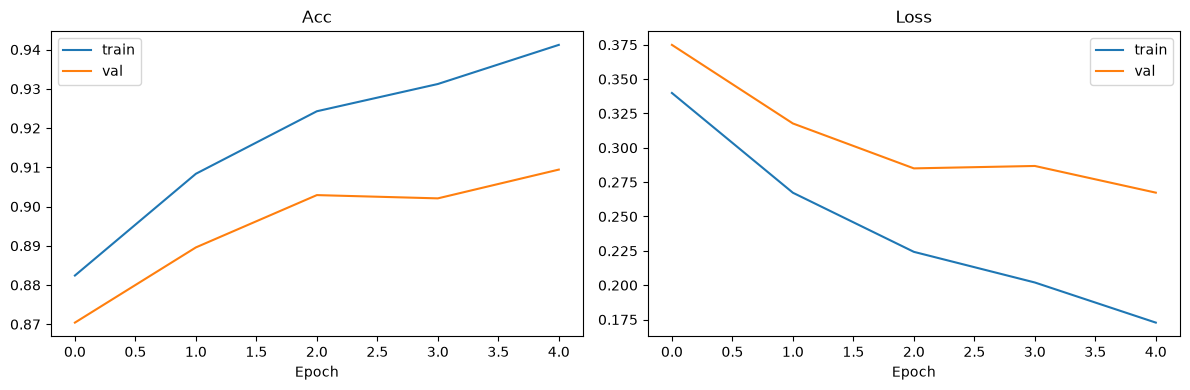


Test accuracy: 0.9079


In [6]:
# ── learning curves ──────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["acc", "loss"]):
    ax.plot(history[f"train_{metric}"], label="train")
    ax.plot(history[f"val_{metric}"],   label="val")
    ax.set_title(metric.capitalize())
    ax.set_xlabel("Epoch")
    ax.legend()
plt.tight_layout()
plt.show()

_, transformer_test_acc = evaluate(model, test_loader, nn.CrossEntropyLoss())
print(f"\nTest accuracy: {transformer_test_acc:.4f}")

### Confusion matrix

With 4 classes, overall accuracy hides which topics the model confuses.

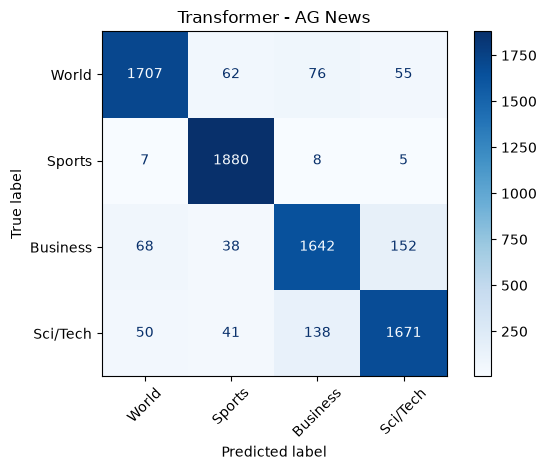

In [7]:
model.eval()
preds_all, labels_all = [], []
with torch.no_grad():
    for x, y in test_loader:
        preds_all.extend(model(x.to(device)).argmax(dim=1).cpu().numpy())
        labels_all.extend(y.numpy())

cm = confusion_matrix(labels_all, preds_all)
ConfusionMatrixDisplay(cm, display_labels=LABEL_NAMES).plot(cmap="Blues", xticks_rotation=45)
plt.title("Transformer - AG News")
plt.tight_layout()
plt.show()

---
# Part 2 — Zero-shot and Few-shot with an LLM

Instead of training a model, we **prompt** a large pretrained language model to classify text — no gradient
descent, no labelled training set.

We use the **Groq API** (free tier) with a LLaMA model.
Install: `pip install groq` — get a key at https://console.groq.com

| Strategy | Labelled examples in prompt | Weight updates |
|---|---|---|
| **Zero-shot** | 0 | None |
| **Few-shot** | K per class | None |

## 2.1 Setup

**Do not paste your API key into the notebook** — set it as an environment variable before starting Jupyter:

```bash
export GROQ_API_KEY="gsk_..."      # Linux / macOS
setx GROQ_API_KEY "gsk_..."        # Windows (then reopen the terminal)
```

In [8]:
%pip install groq


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [9]:
from groq import Groq
import random

GROQ_API_KEY = os.environ.get("GROQ_API_KEY")
if not GROQ_API_KEY:
    GROQ_API_KEY = "your-api-key-here"   # fallback for the class; delete before sharing

# Model names on hosted APIs change often; check https://console.groq.com/docs/models
MODEL = "qwen/qwen3.8-27b"

random.seed(SEED)

N_TEST            = 20   # samples to classify
N_TRAIN_PER_CLASS = 2    # demonstrations per class -> 8 in total (balanced)

raw = load_dataset("fancyzhx/ag_news")

# Balanced demonstrations: the same number of examples from each class, so the prompt
# does not suggest that one topic is more likely than another.
demos = []
for label_id in range(NUM_CLASSES):
    subset = [s for s in raw["train"].select(range(2000)) if s["label"] == label_id]
    random.shuffle(subset)
    demos.extend(subset[:N_TRAIN_PER_CLASS])
random.shuffle(demos)

test_data = raw["test"].shuffle(seed=SEED).select(range(N_TEST))
true_labels = [s["label"] for s in test_data]

print(f"Demonstrations: {len(demos)}  ({N_TRAIN_PER_CLASS} per class)")
print(f"Test examples to classify: {len(test_data)}")
print(f"Class counts in the test sample: {np.bincount(true_labels, minlength=4).tolist()}")

Demonstrations: 8  (2 per class)
Test examples to classify: 20
Class counts in the test sample: [5, 5, 6, 4]


In [10]:
client = Groq(api_key=GROQ_API_KEY)

def call_llm(prompt: str, model: str = MODEL) -> str:
    resp = client.chat.completions.create(
        model=model,
        messages=[{"role": "user", "content": prompt}],
        temperature=0,    # deterministic: we want a classification, not creative writing
        max_tokens=8,     # we only expect a single digit
    )
    return resp.choices[0].message.content

In [11]:
def classify(prompt_builder, data, show=True):
    """Call the LLM once per example and parse a single 0-3 out of each answer."""
    preds = []
    for sample in data:
        response = call_llm(prompt_builder(sample))
        match = re.search(r"\b([0-3])\b", response.strip())
        preds.append(int(match.group(1)) if match else -1)   # -1 = unparseable
        if show:
            print(f"  -> {preds[-1]}  (gt={sample['label']}  raw='{response.strip()[:30]}')")
    return preds

def accuracy(preds, targets):
    return sum(p == t for p, t in zip(preds, targets)) / len(targets)

def report(label, preds, targets):
    print(f"Predicted    ({len(preds)}): {preds}")
    print(f"Ground truth ({len(targets)}): {targets}")
    if -1 in preds:
        print(f"{preds.count(-1)} unparseable response(s), counted as wrong")
    print(f"{label} accuracy: {accuracy(preds, targets):.2%}")

## 2.2 Zero-shot classification

We describe the task in the prompt without providing any labelled examples. The LLM relies entirely on knowledge
acquired during pre-training.

We send **one article per call**: asking for 20 answers in a single call is cheaper, but the answers easily drift
out of alignment with the inputs, and one missing item shifts every label after it.

The 4 classes are: **0 = World, 1 = Sports, 2 = Business, 3 = Sci/Tech**.

In [12]:
def build_zero_shot_prompt(sample):
    # TODO 7 — build a zero-shot prompt for ONE article. It should:
    #   1. explain the task and list the 4 categories with their integer codes
    #      (0 = World, 1 = Sports, 2 = Business, 3 = Sci/Tech)
    #   2. include the article text (truncated, e.g. sample["text"][:400])
    #   3. ask for ONLY a single integer as the answer, so it can be parsed reliably
    # Return the prompt string.
    prompt  = "Classify the following news article into exactly one of these 4 categories:\n"
    prompt += "0 = World\n1 = Sports\n2 = Business\n3 = Sci/Tech\n\n"
    prompt += f"Article: {sample['text'][:400]}\n\n"
    prompt += "Output ONLY a single integer: 0, 1, 2 or 3."
    return prompt

print("=== Zero-shot prompt ===")
print(build_zero_shot_prompt(test_data[0]), "\n")

zs_preds = classify(build_zero_shot_prompt, test_data)

=== Zero-shot prompt ===
Classify the following news article into exactly one of these 4 categories:
0 = World
1 = Sports
2 = Business
3 = Sci/Tech

Article: Indian board plans own telecast of Australia series The Indian cricket board said on Wednesday it was making arrangements on its own to broadcast next month #39;s test series against Australia, which is under threat because of a raging TV rights dispute.

Output ONLY a single integer: 0, 1, 2 or 3. 



  -> 1  (gt=1  raw='1')


  -> 2  (gt=2  raw='2')


  -> 1  (gt=1  raw='1')
  -> 2  (gt=2  raw='2')


  -> 3  (gt=3  raw='3')


  -> 2  (gt=0  raw='2')
  -> 2  (gt=2  raw='2')


... (3 outputs left out)

  -> 0  (gt=0  raw='0')
  -> 2  (gt=2  raw='2')


  -> 0  (gt=3  raw='0')
  -> 0  (gt=0  raw='0')


  -> 1  (gt=1  raw='1')
  -> 0  (gt=0  raw='0')


  -> 3  (gt=3  raw='3')


In [13]:
report("Zero-shot", zs_preds, true_labels)

Predicted    (20): [1, 2, 1, 2, 3, 2, 2, 2, 3, 2, 0, 1, 1, 0, 2, 0, 0, 1, 0, 3]
Ground truth (20): [1, 2, 1, 2, 3, 0, 2, 2, 3, 2, 0, 1, 1, 0, 2, 3, 0, 1, 0, 3]
Zero-shot accuracy: 90.00%


## 2.3 Few-shot classification

We now add a few labelled examples at the beginning of the prompt. This is **in-context learning** — the model
adapts its behaviour without updating any weights.

In [14]:
def build_few_shot_prompt(sample, demonstrations=demos):
    # TODO 8 — build a few-shot prompt for ONE article. Same as TODO 7, plus:
    #   between the task description and the article, show each demonstration as
    #   "Article: <text[:200]>" followed by "Label: <label> (<LABEL_NAMES[label]>)"
    #   use a separator (e.g. "--------") before the article to classify
    # Return the prompt string.
    prompt  = "Classify a news article into exactly one of these 4 categories:\n"
    prompt += "0 = World\n1 = Sports\n2 = Business\n3 = Sci/Tech\n\n"
    prompt += "Here are some labelled examples:\n\n"
    for demo in demonstrations:
        prompt += f"Article: {demo['text'][:200]}\n"
        prompt += f"Label: {demo['label']} ({LABEL_NAMES[demo['label']]})\n\n"
    prompt += "--------\n"
    prompt += f"Article: {sample['text'][:400]}\n\n"
    prompt += "Output ONLY a single integer: 0, 1, 2 or 3."
    return prompt

print("=== Few-shot prompt (first 800 chars) ===")
print(build_few_shot_prompt(test_data[0])[:800], "...\n")

fs_preds = classify(build_few_shot_prompt, test_data)

=== Few-shot prompt (first 800 chars) ===
Classify a news article into exactly one of these 4 categories:
0 = World
1 = Sports
2 = Business
3 = Sci/Tech

Here are some labelled examples:

Article: Animating for the Super Bowl Against an impossible deadline, a small team at Sony Cinematics Solutions Group created a two-minute animated promo to prove that a tech-savvy group could do dazzling broa
Label: 3 (Sci/Tech)

Article: Halliburton Says Army Suspends Withhold Threat  WASHINGTON (Reuters) - Halliburton said on Monday the U.S.  Army had decided to give the company more time to resolve a  billing dispute before withhold
Label: 2 (Business)

Article: American Allies Embrace U.S. Military Plan (AP) AP - American allies Japan and Australia embraced a new U.S. plan to restructure its forces abroad, while Russia said it was not concer ...

  -> 1  (gt=1  raw='1')


  -> 2  (gt=2  raw='2')


  -> 1  (gt=1  raw='1')


  -> 2  (gt=2  raw='2')


  -> 3  (gt=3  raw='3')


  -> 2  (gt=0  raw='2')


... (9 outputs left out)

  -> 0  (gt=0  raw='0')


  -> 1  (gt=1  raw='1')


  -> 0  (gt=0  raw='0')


  -> 3  (gt=3  raw='3')


In [15]:
report(f"Few-shot ({len(demos)} demos)", fs_preds, true_labels)

Predicted    (20): [1, 2, 1, 2, 3, 2, 2, 2, 3, 2, 0, 1, 1, 0, 2, 3, 0, 1, 0, 3]
Ground truth (20): [1, 2, 1, 2, 3, 0, 2, 2, 3, 2, 0, 1, 1, 0, 2, 3, 0, 1, 0, 3]
Few-shot (8 demos) accuracy: 95.00%


## 2.4 A fair comparison

The transformer was evaluated on the full 7 600-article test set, while the LLM saw only `N_TEST` articles.
To compare like with like, we run the trained transformer on exactly the same articles.

In [16]:
x = torch.stack([encode(s["text"], word_index, MAX_LEN) for s in test_data]).to(device)
model.eval()
with torch.no_grad():
    tr_preds = model(x).argmax(dim=1).cpu().tolist()

report(f"Transformer (same {N_TEST} samples)", tr_preds, true_labels)
print(f"\nTransformer on the full test set: {transformer_test_acc:.2%}")

Predicted    (20): [1, 2, 1, 2, 3, 2, 2, 2, 3, 3, 0, 1, 1, 0, 2, 3, 0, 1, 0, 3]
Ground truth (20): [1, 2, 1, 2, 3, 0, 2, 2, 3, 2, 0, 1, 1, 0, 2, 3, 0, 1, 0, 3]
Transformer (same 20 samples) accuracy: 90.00%

Transformer on the full test set: 90.79%


## 2.5 Summary and questions

| Approach | Labelled data | Trained parameters | Accuracy |
|---|---|---|---|
| Transformer trained from scratch | ~108 000 | ~1.5 M | |
| LLM zero-shot | 0 | none | |
| LLM few-shot | 8 | none | |

> `N_TEST` samples is a very small test set — treat the differences as indicative only.

Questions:

1. Which classes does the transformer confuse most (confusion matrix)? Does the LLM make the same mistakes?
2. Does few-shot beat zero-shot here? On an easy, well-known task, a strong model may already be at its ceiling
   zero-shot — the demonstrations then mostly fix the *output format*.
3. AG News has ~108 000 training articles. Train on 5 000 instead (`train_frac` or a `select`) and compare again
   with the LLM. At which training-set size does prompting become the better option?
4. Which approach would you choose for a new classification problem at work, and what would decide it:
   accuracy, cost per 1 000 documents, latency, privacy, or reproducibility?